In [1]:
# ============================================================
# ASSIGNMENT No. 06
# Agricultural Genomics and Crop Improvement
# ============================================================

# Section 1: Import Required Libraries
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import chi2_contingency
from scipy.stats import pearsonr

print("Libraries imported successfully!")

Libraries imported successfully!


In [5]:
# ============================================================
#  Load XML File Paths
# ============================================================

import os
import glob

# Dataset paths
train_path = "archive6/XML/train"
test_path = "archive6/XML/test"

# Get all XML files
train_files = glob.glob(os.path.join(train_path, "*.xml"))
test_files = glob.glob(os.path.join(test_path, "*.xml"))

# Display information
print("Training XML files:", len(train_files))
print("Testing XML files:", len(test_files))
print("Total XML files:", len(train_files) + len(test_files))

print("\nFirst 5 Training Files:")
for file in train_files[:5]:
    print(file)

print("\nFirst 5 Testing Files:")
for file in test_files[:5]:
    print(file)

Training XML files: 270
Testing XML files: 90
Total XML files: 360

First 5 Training Files:
archive6/XML/train\Abs_0.xml
archive6/XML/train\Abs_1.xml
archive6/XML/train\Abs_10.xml
archive6/XML/train\Abs_100.xml
archive6/XML/train\Abs_101.xml

First 5 Testing Files:
archive6/XML/test\Abs_0.xml
archive6/XML/test\Abs_1.xml
archive6/XML/test\Abs_10.xml
archive6/XML/test\Abs_11.xml
archive6/XML/test\Abs_12.xml


In [6]:

import xml.etree.ElementTree as ET
import re

associations = []

for file in train_files:
    tree = ET.parse(file)
    root = tree.getroot()

    text = " ".join(
        element.text.strip()
        for element in root.iter()
        if element.text and element.text.strip()
    )

    # Find SNP mentions
    snps = re.findall(r'\brs\d+\b|\bSNP[-_]?\w+\b', text, re.IGNORECASE)

    # Find phenotype/trait-related text
    phenotypes = re.findall(
        r'\b(?:disease resistance|yield|phenotype|trait|resistance|susceptibility)\b',
        text,
        re.IGNORECASE
    )

    for snp in set(snps):
        for phenotype in set(phenotypes):
            associations.append([snp, phenotype])

association_df = pd.DataFrame(
    associations,
    columns=["SNP", "Phenotype"]
)

print("Total SNP-Phenotype associations:", len(association_df))
print("\nFirst 10 associations:")
print(association_df.head(10))

Total SNP-Phenotype associations: 0

First 10 associations:
Empty DataFrame
Columns: [SNP, Phenotype]
Index: []


In [9]:


import xml.etree.ElementTree as ET

tree = ET.parse(train_files[0])
root = tree.getroot()

for element in root.iter():
    text = element.text.strip() if element.text else ""
    if text:
        print(element.tag, ":", text[:150])

In [11]:
# ============================================================
# Section 7: Extract SNP-Phenotype Associations
# ============================================================

import xml.etree.ElementTree as ET

associations = []

for file in train_files:
    tree = ET.parse(file)
    root = tree.getroot()

    for pair in root.iter("pair"):

        snp_id = pair.get("SNPID")
        phenotype_id = pair.get("PHENOTYPEID")
        association = pair.get("ASSOCIATION")
        confidence = pair.get("CONFIDENCE")

        # Find corresponding SNP and phenotype
        snp_text = ""
        phenotype_text = ""

        for snp in root.iter("snp"):
            if snp.get("ID") == snp_id:
                snp_text = snp.get("TEXT")
                break

        for phenotype in root.iter("phenotype"):
            if phenotype.get("ID") == phenotype_id:
                phenotype_text = phenotype.get("text")
                break

        associations.append([
            snp_text,
            phenotype_text,
            association,
            confidence
        ])

# Create DataFrame
association_df = pd.DataFrame(
    associations,
    columns=["SNP", "Phenotype", "Association", "Confidence"]
)

print("Total associations:", len(association_df))

print("\nFirst 10 associations:")
print(association_df.head(10))

Total associations: 935

First 10 associations:
         SNP                                          Phenotype Association  \
0  rs1051730                                nicotine metabolism     neutral   
1  rs1051730                       fetal growth characteristics    positive   
2  rs1051730                        fetal growth characteristic    negative   
3  rs1051730                                 head circumference    negative   
4  rs1051730      second and third trimester fetal femur length    positive   
5  rs1051730                               smaller birth length    positive   
6  rs1051730  lower third trimester estimated fetal weight [...    positive   
7  rs1051730                                       birth weight    positive   
8  rs1051730          impairedfetal growth in length and weight    positive   
9  rs1051730                            blood mononuclear cells    positive   

  Confidence  
0       zero  
1       weak  
2          -  
3          -  
4      

In [12]:
# ============================================================
# Section 8: Analyze SNP-Phenotype Associations
# ============================================================

association_counts = association_df["Association"].value_counts()

print("Association Summary:")
print(association_counts)

print("\nPercentage of Each Association Type:")
print(
    (association_counts / len(association_df) * 100).round(2)
)

Association Summary:
Association
positive    702
neutral     142
negative     91
Name: count, dtype: int64

Percentage of Each Association Type:
Association
positive    75.08
neutral     15.19
negative     9.73
Name: count, dtype: float64


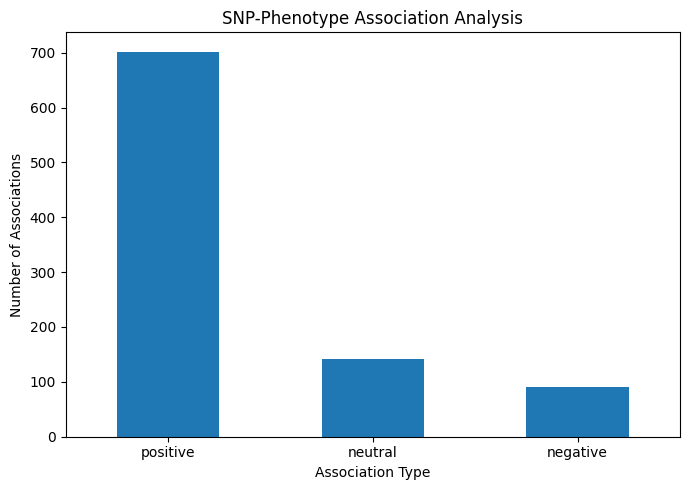

In [13]:
# ============================================================
# Section 9: Visualize SNP-Phenotype Associations
# ============================================================

import matplotlib.pyplot as plt

association_counts.plot(
    kind="bar",
    figsize=(7, 5)
)

plt.title("SNP-Phenotype Association Analysis")
plt.xlabel("Association Type")
plt.ylabel("Number of Associations")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [14]:
# ============================================================
# Section 10: Most Frequent SNPs
# ============================================================

snp_counts = association_df["SNP"].value_counts().head(10)

print("Top 10 SNPs:")
print(snp_counts)

Top 10 SNPs:
SNP
rs7903146     90
rs12255372    78
rs1051730     44
rs429358      28
rs7901695     23
APOE          21
rs7412        21
APOA5         16
rs1800775     15
rs11196205    13
Name: count, dtype: int64


In [15]:
# ============================================================
# Section 11: Chi-Square Association Test
# ============================================================

from scipy.stats import chi2_contingency

# Create contingency table for top 10 SNPs
top_snps = association_df["SNP"].value_counts().head(10).index

table = pd.crosstab(
    association_df[association_df["SNP"].isin(top_snps)]["SNP"],
    association_df[association_df["SNP"].isin(top_snps)]["Association"]
)

print("Contingency Table:")
print(table)

# Chi-square test
chi2, p_value, degrees_of_freedom, expected = chi2_contingency(table)

print("\nChi-square statistic:", round(chi2, 4))
print("Degrees of freedom:", degrees_of_freedom)
print("P-value:", round(p_value, 6))

Contingency Table:
Association  negative  neutral  positive
SNP                                     
APOA5               0        0        16
APOE                4        3        14
rs1051730           4        7        33
rs11196205          2        7         4
rs12255372          9       12        57
rs1800775           0        0        15
rs429358            4        4        20
rs7412              2        2        17
rs7901695           1        7        15
rs7903146          11       12        67

Chi-square statistic: 34.5787
Degrees of freedom: 18
P-value: 0.010675


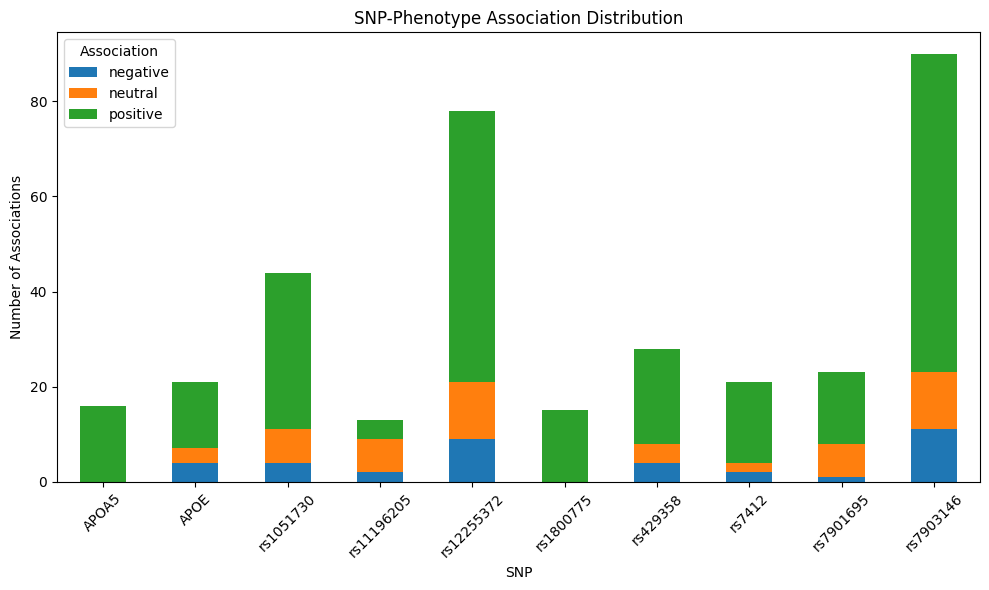

In [16]:
# ============================================================
# Section 12: SNP-Association Distribution
# ============================================================

table.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6)
)

plt.title("SNP-Phenotype Association Distribution")
plt.xlabel("SNP")
plt.ylabel("Number of Associations")
plt.xticks(rotation=45)
plt.legend(title="Association")
plt.tight_layout()
plt.show()

In [17]:
# ============================================================
# Section 13: Save Association Results
# ============================================================

output_file = "SNP_Phenotype_Associations.csv"

association_df.to_csv(output_file, index=False)

print("Results saved successfully!")
print("File:", output_file)
print("Rows:", len(association_df))
print("Columns:", list(association_df.columns))

Results saved successfully!
File: SNP_Phenotype_Associations.csv
Rows: 935
Columns: ['SNP', 'Phenotype', 'Association', 'Confidence']
